# Static Planning Agent — One Graph with Parallel Execution

**Flow:** User Request → Static Planner → Fan-out → Parallel Section Workers → Fan-in → Final Report

The planner creates the complete plan once. Each section is then processed independently.

### Important correction

The previous version put per-section values such as `search_queries`, `source_str`, and `current_section` into the shared graph state. Multiple `Send` branches then wrote those same `LastValue` channels, causing:

`InvalidUpdateError: At key 'search_queries': Can receive only one value per step.`

This notebook fixes that by making each parallel worker responsible for the complete section workflow:

**Section → Generate Queries → Search → Write**

Only `completed_sections` is returned to shared graph state, and it uses a reducer.

In [42]:
import os
import asyncio
import operator
from typing import List, Annotated
from typing_extensions import TypedDict
from pydantic import BaseModel
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from dotenv import load_dotenv
from tavily import TavilyClient
from typing import List



In [2]:
load_dotenv()

True

In [41]:
llm = ChatOpenAI(model="gpt-4o",temperature=0)
tavily_api = os.getenv("TAVILY_API_KEY")
tavily = TavilySearchAPIWrapper()

##tavily = TavilyClient(api_key=tavily_api)

In [37]:
tavily_api

'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'

## 1. Structured outputs

The planner creates sections. The query generator creates search queries for one section.

In [5]:
class Section(BaseModel):
    name:str
    description:str
    research:bool = True
    content:str = ""

class Sections(BaseModel):
    sections:List[Section]

class SearchQuery(BaseModel):
    search_query:str

class Queries(BaseModel):
    queries:List[SearchQuery]
    
        

## 2. Graph state

`ReportState` is the shared state of the main graph.

`WorkerState` is the input to one parallel worker.

Notice that `search_queries`, `source_str`, and `current_section` are **not** shared graph-state fields.

In [7]:
class ReportState(TypedDict):
    topic:str
    sections:List[Section]
    combined_section:Annotated[List[Section], operator.add]
    final_report:str

class WorkerState(TypedDict):
    topic:str
    section:Section

## 3. Static Planner

The planner runs once and creates the complete plan before section execution begins.

In [15]:
PLANNER_PROMPT = """
You are a planning agent.

Create a plan for a report about the given topic.
Break the topic into 4 to 5 logical sections.

For each section provide:
- name
- short description
- whether web research is required

Do not write the report. Only create the plan.
"""
def create_plan(state: ReportState):
    structured_llm = llm.with_structured_output(Sections)
    response = structured_llm.invoke([
        SystemMessage(content=PLANNER_PROMPT),
        HumanMessage(
            content=f"Create a report plan for:\n\n{state['topic']}"
        )
    ])
    print("\n" + "=" * 60)
    print("STATIC PLAN")
    print("=" * 60)
    
    # Access the sections from the response
    sections = response.sections if hasattr(response, 'sections') else response[0].sections
    
    for i, section in enumerate(sections):
        print(f"{i}. {section.name}")
        print(f" {section.description}")
    
    return {"sections": sections}

In [16]:
# Lets test the function:
state = {
    "topic": "Explain Agentic AI, its components, design patterns, applications and challenges"
}
result = create_plan(state)
print(result)


STATIC PLAN
0. Introduction to Agentic AI
 This section will provide an overview of what Agentic AI is, including its definition and significance in the field of artificial intelligence.
1. Components of Agentic AI
 This section will delve into the various components that make up Agentic AI, such as perception, reasoning, learning, and action.
2. Design Patterns in Agentic AI
 This section will explore the common design patterns used in developing Agentic AI systems.
3. Applications of Agentic AI
 This section will highlight the various applications of Agentic AI across different industries and domains.
4. Challenges in Agentic AI
 This section will discuss the challenges faced in the development and deployment of Agentic AI systems.
{'sections': [Section(name='Introduction to Agentic AI', description='This section will provide an overview of what Agentic AI is, including its definition and significance in the field of artificial intelligence.', research=True, content='Define Agentic 

## 4. Generate search queries

This is a normal helper function, not a graph node. Its data stays local to the current worker.

In [17]:
QUERY_PROMPT="""
You are a reasearch assistant.

generate 3 useful web search queries for the given report section
the queries help find relevant and reliable information
"""

def generate_queries(section: Section) -> List[SearchQuery]:
    structured_llm  = llm.with_structured_output(Queries)
    
    response  = structured_llm.invoke([
        SystemMessage(content=QUERY_PROMPT),
        HumanMessage(content = f"""
                     Section: {section.name}
                     Description: {section.description}
                     
                     Generate 3 search queries
                     """ )
    ])
    return response.queries
    

In [18]:
# Lets test the function:
section = Section(
    name="Core Components of Agentic AI",
    description="""
    Explain the main components that enable an AI agent
    to reason, plan, remember, use tools, and execute tasks.
    """
)

result = generate_queries(section)

print(result)

[SearchQuery(search_query='Core components of AI agents for reasoning and planning'), SearchQuery(search_query='How AI agents use memory and tools for task execution'), SearchQuery(search_query='Key elements of agentic AI systems for effective task management')]


## 5. Search the web

The queries for one section are also executed concurrently with `asyncio.gather`.

So the example demonstrates two levels of parallelism:

1. LangGraph parallelism — different report sections.
2. Async search parallelism — multiple searches within one section.

In [43]:



async def run_search_query(
    queries: List[SearchQuery],
    num_result: int = 5
):
    tasks = [
        asyncio.to_thread(
            tavily.raw_results,
            query.search_query,
            max_results=num_result,
            search_depth="advanced",
            include_answer=False
        )
        for query in queries
    ]

    return await asyncio.gather(*tasks)

In [20]:
def format_search_results(search_results) -> str:
    formatted = ""

    for result in search_results:
        for item in result.get("results", []):
            formatted += (
                f"Source: {item.get('title', 'Unknown')}\n"
                f"URL: {item.get('url', '')}\n\n"
                f"Content:\n{item.get('content', '')}\n\n"
                "-------------------------\n"
            )

    return formatted

In [ ]:
# Lets test there function together:
queries = [
    SearchQuery(search_query="what is Agentic AI"),
    SearchQuery(search_query="core components of Agentic AI"),
    SearchQuery(search_query="Agentic AI design patterns")
]

search_results = await run_search_query(
    queries,
    num_results=5
)

source_str = format_search_results(search_results)

#print(source_str)

## 6. Write one section

The section and research are local variables. Nothing here writes per-section data to shared graph state.

In [21]:
WRITER_PROMPT = """
You are a technical writer.

Write one section of a report using the research provided.

Rules:
- Use simple and clear language.
- Focus only on the requested section.
- Use the research information provided.
- Do not invent facts.
"""
def write_section(section: Section, source_str: str) -> Section:
    response = llm.invoke([
        SystemMessage(content=WRITER_PROMPT),
        HumanMessage(
            content=f"""
Section:
{section.name}

Description:
{section.description}

Research:
{source_str}

Write the section.
"""
        )
    ])

    section.content = response.content
    return section

In [22]:
#Lets test this function:
section = Section(
    name="Core Components of Agentic AI",
    description="Explain the main components of Agentic AI."
)

source_str = """
Agentic AI systems typically combine capabilities such as
planning, memory, tool use, reasoning, and execution.

Memory allows an agent to retain relevant information.
Tools allow the agent to interact with external systems.
Planning helps break complex goals into smaller tasks.
"""

result = write_section(
    section,
    source_str
)

print(result.content)

### Core Components of Agentic AI

Agentic AI systems are designed to perform tasks autonomously by integrating several key components. These components work together to enable the AI to function effectively and achieve its objectives.

1. **Planning**: This component allows the AI to break down complex goals into smaller, manageable tasks. By planning, the AI can determine the steps needed to achieve its objectives and organize these steps in a logical sequence. This capability is crucial for handling intricate tasks that require a structured approach.

2. **Memory**: Memory is essential for an AI to retain relevant information over time. It enables the AI to recall past interactions, learn from previous experiences, and apply this knowledge to future tasks. This component ensures that the AI can adapt and improve its performance based on historical data.

3. **Tool Use**: The ability to use tools allows the AI to interact with external systems and environments. By leveraging various 

## 7. Parallel Section Worker

This is the key design change.

One worker performs the entire workflow for one section:

**Generate Queries → Search → Write**

The worker returns only its completed section.

Because workers do not write `search_queries` or `source_str` into shared state, there is no concurrent update conflict for those fields.

In [23]:
async def process_section(state: WorkerState):
    section = state["section"]

    print(f"\n[Worker started] {section.name}")

    # 1. Generate queries for this section
    queries = generate_queries(section)
    print(f"[Queries generated] {section.name}: {len(queries)}")

    # 2. Research this section
    search_results = await run_search_query(queries)
    source_str = format_search_results(search_results)
    print(f"[Research complete] {section.name}")

    # 3. Write this section
    completed_section = write_section(section, source_str)
    print(f"[Worker finished] {section.name}")

    # Only this result is merged into shared graph state.
    return {
        "completed_sections": [completed_section]
    }

## 8. Fan-out with `Send`

The planner produces the complete list of sections.

`Send` creates one independent worker execution for each section.

Example:

```text
                 Planner
                    |
              Complete Plan
                    |
                 FAN-OUT
          /          |          \
     Section 1   Section 2   Section 3
          \          |          /
                   FAN-IN
```

In [24]:
def fan_out_sections(state: ReportState):
    return [
        Send(
            "process_section",
            {
                "topic": state["topic"],
                "section": section
            }
        )
        for section in state["sections"]
    ]

## 9. Fan-in / combine

`completed_sections` is declared with:

```python
Annotated[List[Section], operator.add]
```

That tells LangGraph how to combine results from concurrent workers.

For example:

```text
Worker 1 → [Section 1]
Worker 2 → [Section 2]
Worker 3 → [Section 3]

              ↓

completed_sections
= [Section 1, Section 2, Section 3]
```

In [45]:
def combine_sections(state: ReportState):
    print("\n" + "=" * 60)
    print("COMBINING SECTIONS")
    print("=" * 60)

    # Ensure 'completed_sections' exists in the state dictionary
    completed_by_name = {
        section.name: section
        for section in state.get("completed_sections", [])
    }

    report_parts = []

    for planned_section in state.get("sections", []):
        section = completed_by_name.get(planned_section.name)

        if section:
            report_parts.append(
                f"## {section.name}\n\n{section.content}"
            )

    return {
        "final_report": "\n\n".join(report_parts)
    }

In [27]:
#Lets test this function:
sections = [
    Section(
        name="Introduction to Agentic AI",
        description="Explain Agentic AI and its basic concepts."
    ),
    Section(
        name="Core Components",
        description="Explain the core components of Agentic AI."
    ),
    Section(
        name="Applications",
        description="Explain applications of Agentic AI."
    )
]

completed_sections = [
    Section(
        name="Introduction to Agentic AI",
        description="Explain Agentic AI and its basic concepts.",
        content="Agentic AI refers to AI systems that can reason, plan and execute tasks."
    ),
    Section(
        name="Core Components",
        description="Explain the core components of Agentic AI.",
        content="Core components include planning, memory, tools, reasoning and execution."
    ),
    Section(
        name="Applications",
        description="Explain applications of Agentic AI.",
        content="Agentic AI can be applied to research, customer support, software development and other workflows."
    )
]

state = {
    "sections": sections,
    "completed_sections": completed_sections
}

result = combine_sections(state)

print(result)


COMBINING SECTIONS
{'final_report': '## Introduction to Agentic AI\n\nAgentic AI refers to AI systems that can reason, plan and execute tasks.\n\n## Core Components\n\nCore components include planning, memory, tools, reasoning and execution.\n\n## Applications\n\nAgentic AI can be applied to research, customer support, software development and other workflows.'}


## 10. Build ONE LangGraph

The graph has only three graph-level stages:

1. `create_plan`
2. `process_section` — executed in parallel using `Send`
3. `combine_sections`

The internal section workflow remains:

**Generate Queries → Research → Write**

In [46]:
graph_builder = StateGraph(ReportState)

graph_builder.add_node("create_plan", create_plan)
graph_builder.add_node("process_section", process_section)
graph_builder.add_node("combine_sections", combine_sections)

# START -> static planner
graph_builder.add_edge(START, "create_plan")

# Planner -> parallel workers
graph_builder.add_conditional_edges(
    "create_plan",
    fan_out_sections,
    ["process_section"]
)

# All worker results -> combine
graph_builder.add_edge(
    "process_section",
    "combine_sections"
)

# Combine -> END
graph_builder.add_edge('combine_sections', END)

report_graph = graph_builder.compile()


## 11. Visualize the graph

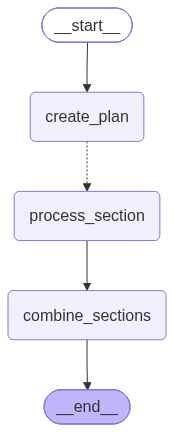

In [29]:
from IPython.display import Image, display

try:
    display(Image(report_graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(report_graph.get_graph().draw_mermaid())
    print("\nGraph image rendering was not available:", e)


## 12. Run the agent

The planner runs first.

After the plan is created, LangGraph fans out to one worker per section. Independent workers can run concurrently.

The final combine node runs after the worker results have been collected.

In [47]:
topic = """
Create a report explaining Agentic AI,
its core components, design patterns,
applications and challenges.
"""

result = await report_graph.ainvoke({
    "topic": topic,
    "sections": [],
    "completed_sections": [],
    "final_report": ""
})


STATIC PLAN
0. Introduction to Agentic AI
 This section will provide an overview of Agentic AI, explaining what it is and its significance in the field of artificial intelligence.
1. Core Components of Agentic AI
 This section will delve into the fundamental components that make up Agentic AI systems.
2. Design Patterns in Agentic AI
 This section will explore the common design patterns used in developing Agentic AI systems.
3. Applications of Agentic AI
 This section will highlight the various applications of Agentic AI across different industries and domains.
4. Challenges in Agentic AI
 This section will address the challenges and limitations faced in the development and deployment of Agentic AI systems.

[Worker started] Introduction to Agentic AI
[Queries generated] Introduction to Agentic AI: 3

[Worker started] Core Components of Agentic AI
[Queries generated] Introduction to Agentic AI: 3

[Worker started] Core Components of Agentic AI
[Queries generated] Core Components of Ag